# Exploratory Data Analysis of the Ames Housing Dataset

**Objective:** Use exploratory data analysis only (no machine learning) to understand which factors drive house sale prices.

**Dataset:** House Prices: Advanced Regression Techniques (Kaggle), file `train.csv`, about 1,460 rows and 81 columns.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [5]:
!mv /train.csv /content/train.csv


mv: cannot stat '/train.csv': No such file or directory


In [6]:
df = pd.read_csv("train.csv")
print("Shape:", df.shape)



Shape: (1460, 81)


In [7]:
display(df.head())
df.info()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
missing_table = pd.DataFrame({"missing_count": missing, "missing_percent": missing_pct})
print(missing_table)
print("\nColumns with missing values:", len(missing_table))

              missing_count  missing_percent
PoolQC                 1453             99.5
MiscFeature            1406             96.3
Alley                  1369             93.8
Fence                  1179             80.8
MasVnrType              872             59.7
FireplaceQu             690             47.3
LotFrontage             259             17.7
GarageType               81              5.5
GarageYrBlt              81              5.5
GarageFinish             81              5.5
GarageQual               81              5.5
GarageCond               81              5.5
BsmtExposure             38              2.6
BsmtFinType2             38              2.6
BsmtQual                 37              2.5
BsmtCond                 37              2.5
BsmtFinType1             37              2.5
MasVnrArea                8              0.5
Electrical                1              0.1

Columns with missing values: 19


In [9]:
numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numeric columns: 38
Categorical columns: 43


In [10]:
ordinal_map = {
    "ExterQual":   ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}
for column, order in ordinal_map.items():
    df[column] = pd.Categorical(df[column], categories=order, ordered=True)

print(df["ExterQual"].dtype)
print(df["ExterQual"].cat.categories)

category
Index(['Po', 'Fa', 'TA', 'Gd', 'Ex'], dtype='object')


In [11]:
summary = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "unique_values": df.nunique(),
    "example_values": [list(df[c].dropna().unique()[:3]) for c in df.columns]
})

summary.index.name = "column"
display(summary)

,type,unique_values,example_values
column,,,
Id,int64,1460,"[1, 2, 3]"
MSSubClass,int64,15,"[60, 20, 70]"
MSZoning,object,5,"[RL, RM, C (all)]"
LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...
MoSold,int64,12,"[2, 5, 9]"
YrSold,int64,5,"[2008, 2007, 2006]"
SaleType,object,9,"[WD, New, COD]"


In [12]:
print(df["OverallQual"].dtype)
print(sorted(df["OverallQual"].unique()))

int64
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [13]:
display(df.describe())

column,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [14]:
for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col]

    mean = s.mean()
    median = s.median()
    mode = s.mode()[0]
    std = s.std()
    var = s.var()
    value_range = s.max() - s.min()
    iqr = s.quantile(0.75) - s.quantile(0.25)
    skew = s.skew()
    kurt = s.kurt()

    print("=" * 40)
    print(col)
    print("Mean:     ", round(mean, 2))
    print("Median:   ", round(median, 2))
    print("Mode:     ", mode)
    print("Std:      ", round(std, 2))
    print("Variance: ", round(var, 2))
    print("Range:    ", value_range)
    print("IQR:      ", iqr)
    print("Skewness: ", round(skew, 2))
    print("Kurtosis: ", round(kurt, 2))

    if mean > median:
        print("Note: mean > median, so right skewed")
    elif mean < median:
        print("Note: mean < median, so left skewed")
    else:
        print("Note: mean = median, so roughly symmetric")

SalePrice
Mean:      180921.2
Median:    163000.0
Mode:      140000
Std:       79442.5
Variance:  6311111264.3
Range:     720100
IQR:       84025.0
Skewness:  1.88
Kurtosis:  6.54
Note: mean > median, so right skewed
GrLivArea
Mean:      1515.46
Median:    1464.0
Mode:      864
Std:       525.48
Variance:  276129.63
Range:     5308
IQR:       647.25
Skewness:  1.37
Kurtosis:  4.9
Note: mean > median, so right skewed
LotArea
Mean:      10516.83
Median:    9478.5
Mode:      7200
Std:       9981.26
Variance:  99625649.65
Range:     213945
IQR:       4048.0
Skewness:  12.21
Kurtosis:  203.24
Note: mean > median, so right skewed


In [15]:
for col in ["Neighborhood", "HouseStyle"]:
    print("=" * 40)
    print(col)
    print(df[col].value_counts())
    print("Mode:", df[col].mode()[0])

Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
Mode: NAmes
HouseStyle
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
Mode: 1Story


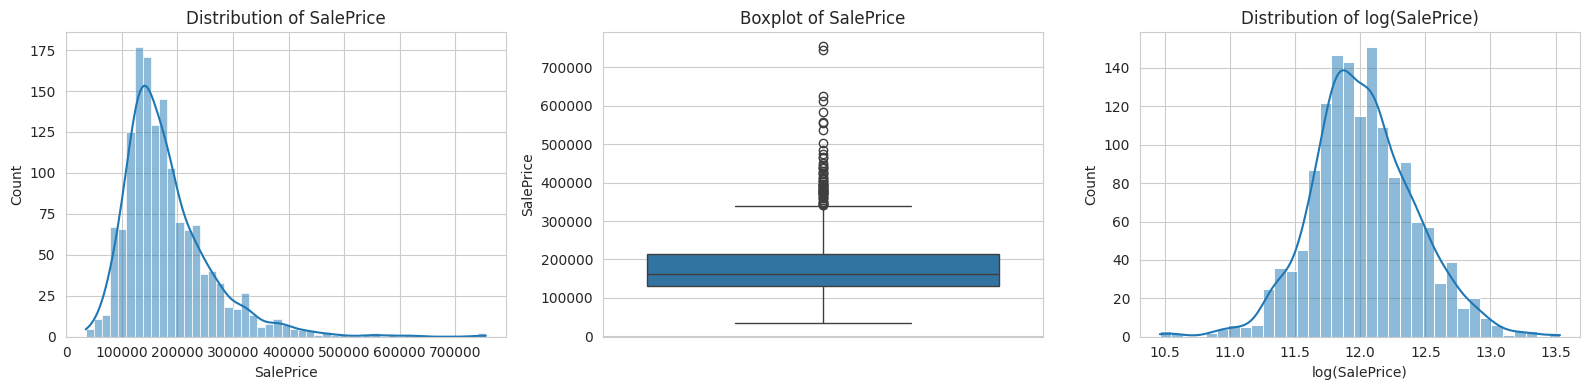

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["SalePrice"], kde=True, ax=ax[0])
ax[0].set_title("Distribution of SalePrice")
ax[0].set_xlabel("SalePrice")
ax[0].set_ylabel("Count")

sns.boxplot(y=df["SalePrice"], ax=ax[1])
ax[1].set_title("Boxplot of SalePrice")
ax[1].set_ylabel("SalePrice")

sns.histplot(np.log(df["SalePrice"]), kde=True, ax=ax[2])
ax[2].set_title("Distribution of log(SalePrice)")
ax[2].set_xlabel("log(SalePrice)")
ax[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [17]:
print("Skewness of SalePrice:      ", round(df["SalePrice"].skew(), 2))
print("Skewness of log(SalePrice): ", round(np.log(df["SalePrice"]).skew(), 2))

Skewness of SalePrice:       1.88
Skewness of log(SalePrice):  0.12


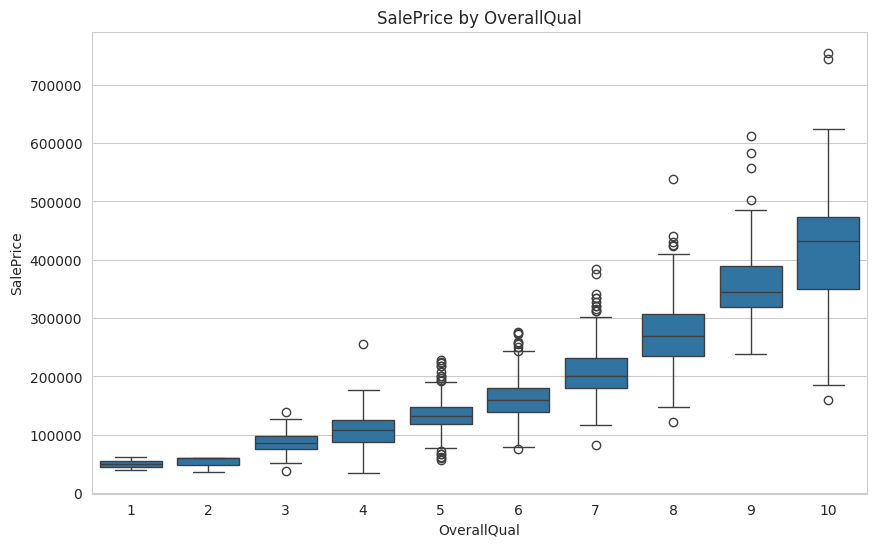

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.title("SalePrice by OverallQual")
plt.xlabel("OverallQual")
plt.ylabel("SalePrice")
plt.show()

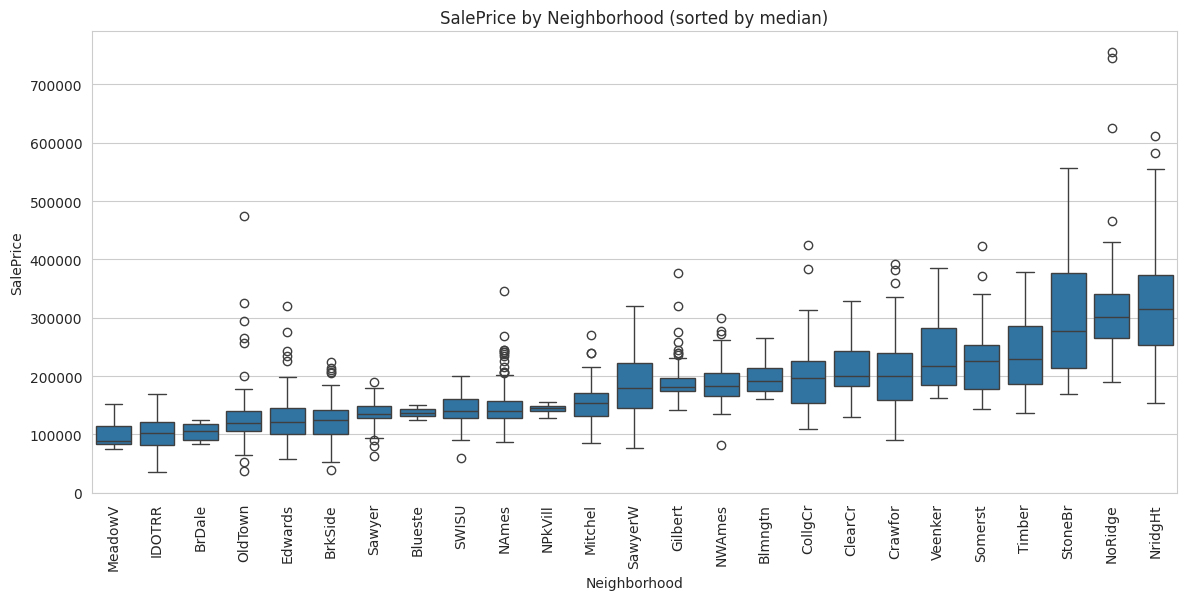

In [19]:
order_n = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 6))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order_n)
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood (sorted by median)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.show()

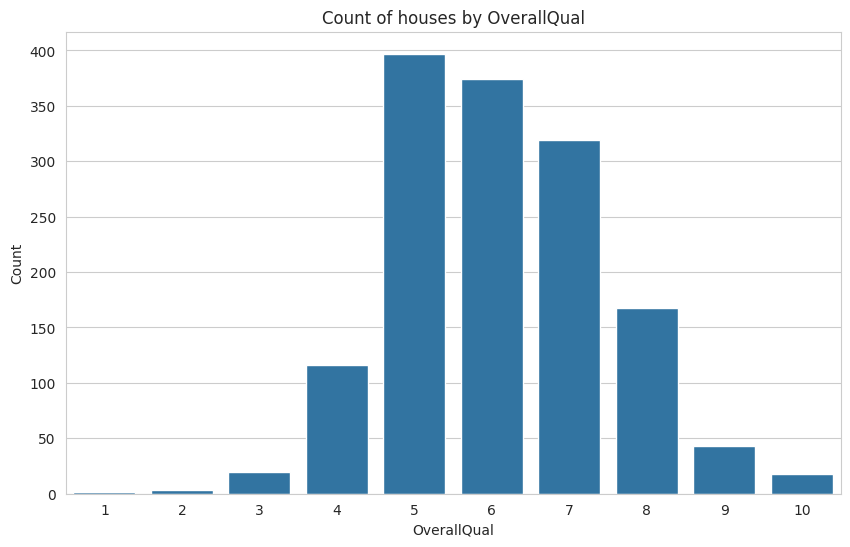

In [20]:
plt.figure(figsize=(10, 6))
sns.countplot(x="OverallQual", data=df)
plt.title("Count of houses by OverallQual")
plt.xlabel("OverallQual")
plt.ylabel("Count")
plt.show()

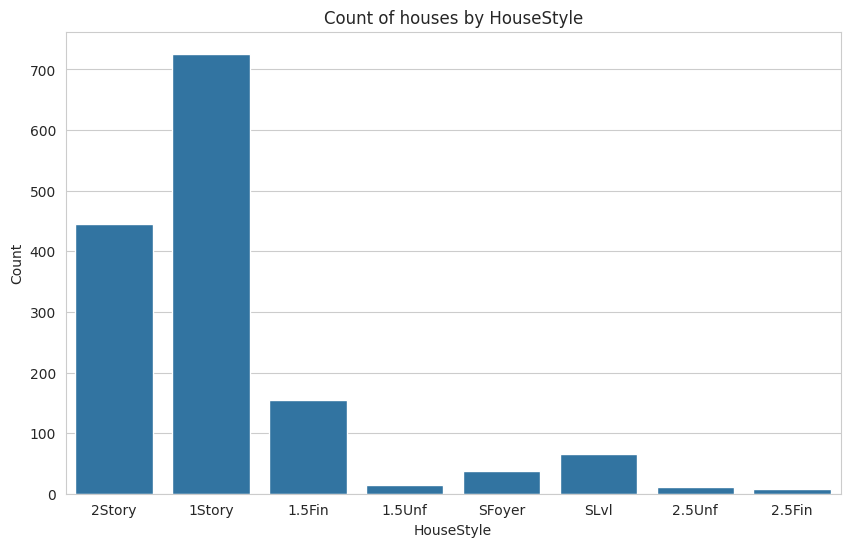

In [21]:
plt.figure(figsize=(10, 6))
sns.countplot(x="HouseStyle", data=df)
plt.title("Count of houses by HouseStyle")
plt.xlabel("HouseStyle")
plt.ylabel("Count")
plt.show()

In [22]:
num = df.select_dtypes(include="number")
cov_matrix = num.cov()
corr_matrix = num.corr()

top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False)
print(top_corr.head(11))




column
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


In [23]:
for f in top_corr.index[1:4]:
    print("=" * 40)
    print(f)
    print("Covariance with SalePrice: ", round(cov_matrix.loc[f, "SalePrice"], 2))
    print("Correlation with SalePrice:", round(corr_matrix.loc[f, "SalePrice"], 3))

OverallQual
Covariance with SalePrice:  86904.13
Correlation with SalePrice: 0.791
GrLivArea
Covariance with SalePrice:  29581866.74
Correlation with SalePrice: 0.709
GarageCars
Covariance with SalePrice:  38020.18
Correlation with SalePrice: 0.64


In [24]:
print(df[["OverallQual", "SalePrice"]].corr(method="spearman"))


column       OverallQual  SalePrice
column                             
OverallQual     1.000000   0.809829
SalePrice       0.809829   1.000000


In [25]:
print(df[["GarageArea", "GarageCars"]].corr())

column      GarageArea  GarageCars
column                            
GarageArea    1.000000    0.882475
GarageCars    0.882475    1.000000


Unusual points: 2


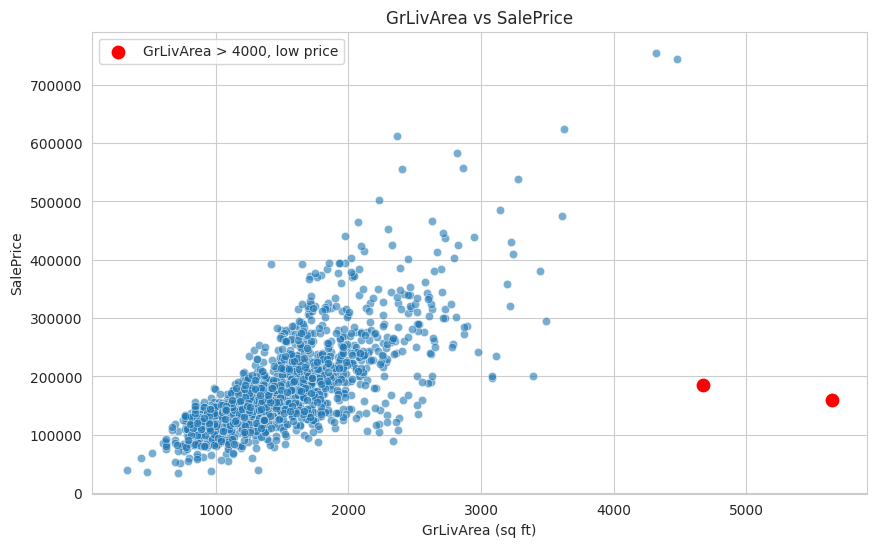

In [26]:
odd = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
print("Unusual points:", len(odd))

plt.figure(figsize=(10, 6))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, alpha=0.6)
plt.scatter(odd["GrLivArea"], odd["SalePrice"], color="red", s=80, label="GrLivArea > 4000, low price")
plt.title("GrLivArea vs SalePrice")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

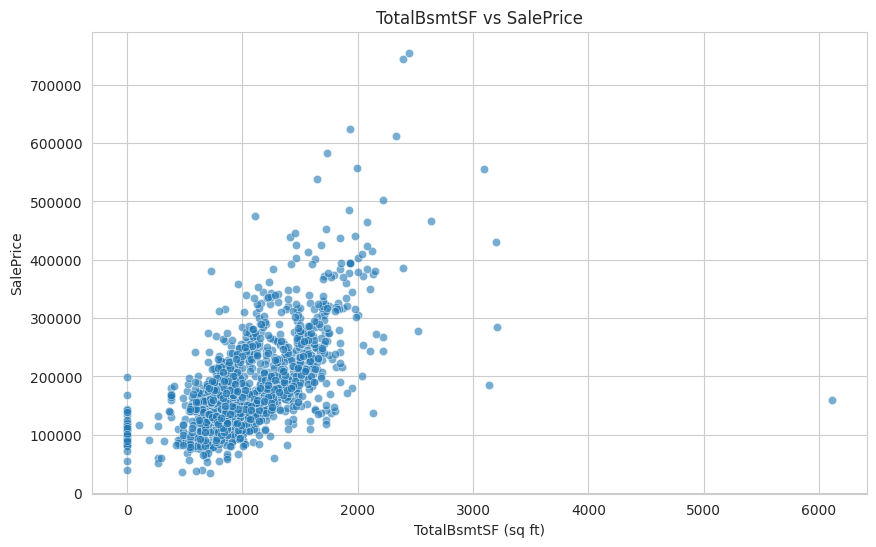

In [27]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df, alpha=0.6)
plt.title("TotalBsmtSF vs SalePrice")
plt.xlabel("TotalBsmtSF (sq ft)")
plt.ylabel("SalePrice")
plt.show()

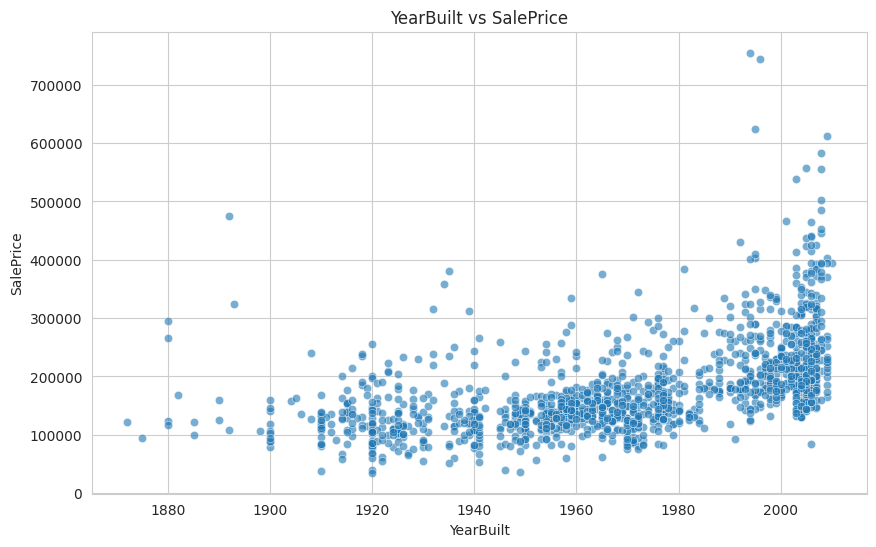

In [28]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="YearBuilt", y="SalePrice", data=df, alpha=0.6)
plt.title("YearBuilt vs SalePrice")
plt.xlabel("YearBuilt")
plt.ylabel("SalePrice")
plt.show()

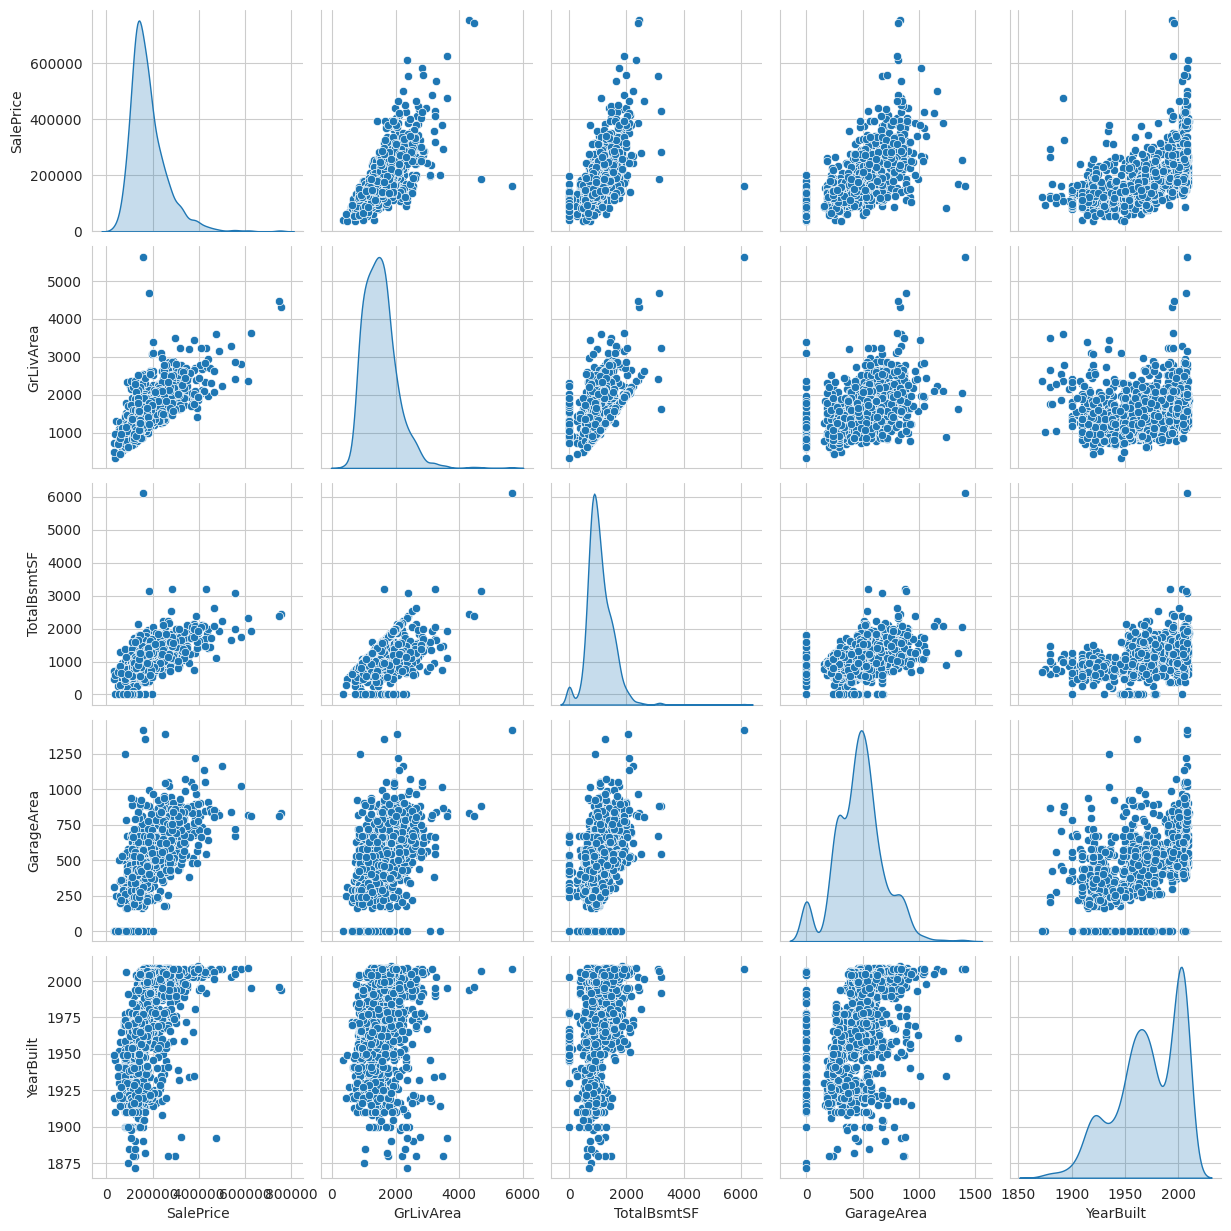

In [29]:
selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
sns.pairplot(df[selected], diag_kind="kde")
plt.show()

In [ ]:
sns.pairplot(df[selected + ["CentralAir"]], hue="CentralAir", diag_kind="kde")
plt.show()

In [ ]:
num = df.select_dtypes(include="number")
corr_matrix = num.corr()
top10 = corr_matrix["SalePrice"].abs().sort_values(ascending=False).head(10).index
corr_top = df[top10].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask)
plt.title("Top 10 features correlated with SalePrice")
plt.show()

In [ ]:
def iqr_outliers(s):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return s[(s < lower) | (s > upper)]

def zscore_outliers(s, threshold=3):
    z = (s - s.mean()) / s.std()
    return s[z.abs() > threshold]

In [ ]:
for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])
    overlap = a.index.intersection(b.index)

    print("=" * 40)
    print(col)
    print("IQR outliers:     ", len(a))
    print("Z-score outliers: ", len(b))
    print("Overlap:          ", len(overlap))

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df["GrLivArea"], ax=ax[0])
ax[0].set_title("GrLivArea boxplot")
sns.boxplot(y=df["SalePrice"], ax=ax[1])
ax[1].set_title("SalePrice boxplot")
plt.tight_layout()
plt.show()

In [ ]:
iqr_idx = iqr_outliers(df["GrLivArea"]).index
z_idx = zscore_outliers(df["GrLivArea"]).index

plt.figure(figsize=(10, 6))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, alpha=0.5, label="Normal")
plt.scatter(df.loc[iqr_idx, "GrLivArea"], df.loc[iqr_idx, "SalePrice"],
            color="orange", s=60, label="IQR outliers")
plt.scatter(df.loc[z_idx, "GrLivArea"], df.loc[z_idx, "SalePrice"],
            color="red", s=60, label="Z-score outliers")
plt.title("GrLivArea vs SalePrice with flagged outliers")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

In [ ]:
to_remove = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index
print("Rows removed:", len(to_remove))

df_clean = df.drop(to_remove)
print("Shape before:", df.shape)
print("Shape after: ", df_clean.shape)

plt.figure(figsize=(10, 6))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df_clean, alpha=0.6)
plt.title("GrLivArea vs SalePrice (after removing unusual sales)")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice")
plt.show()

In [ ]:
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates()
    print("New shape:", df.shape)

for col in categorical_cols:
    values = df[col].dropna().unique()
    cleaned = pd.Series(values).str.strip().str.lower().unique()
    if len(cleaned) != len(values):
        print("Problem in:", col)
print("Check finished")

for col in ["Neighborhood", "HouseStyle", "SaleCondition", "MSZoning"]:
    print(col, sorted(df[col].dropna().unique()))

In [ ]:
for col in ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType"]:
    df[col] = df[col].fillna("None")
other_none_cols = ["MiscFeature", "GarageFinish", "GarageQual", "GarageCond",
                   "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
                   "BsmtFinType2", "MasVnrType"]
for col in other_none_cols:
    df[col] = df[col].fillna("None")

df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median()))
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

In [ ]:
remaining = df.isnull().sum()
print("Total missing values left:", remaining.sum())
print(remaining[remaining > 0])


In [ ]:
print("YearBuilt > YrSold:", (df["YearBuilt"] > df["YrSold"]).sum())
print("YearRemodAdd > YrSold:", (df["YearRemodAdd"] > df["YrSold"]).sum())
print("Negative GrLivArea:", (df["GrLivArea"] < 0).sum())
print("Negative LotArea:", (df["LotArea"] < 0).sum())
print("Negative TotalBsmtSF:", (df["TotalBsmtSF"] < 0).sum())

In [ ]:
df_clean = df.drop(df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index)
print("df shape:      ", df.shape)
print("df_clean shape:", df_clean.shape)

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
color = "steelblue"

# Panel 1: Average price by year built (Matplotlib line plot)
avg_by_year = df.groupby("YearBuilt")["SalePrice"].mean()
ax[0, 0].plot(avg_by_year.index, avg_by_year.values, color=color, label="Average price")
ax[0, 0].set_title("Average price by year built")
ax[0, 0].set_xlabel("Year built")
ax[0, 0].set_ylabel("Average SalePrice")
ax[0, 0].legend()
# Panel 2: Top 10 neighborhoods by mean price (Matplotlib horizontal bar plot)
top = df.groupby("Neighborhood")["SalePrice"].mean().nlargest(10).sort_values()
ax[0, 1].barh(top.index, top.values, color=color)
ax[0, 1].set_title("Top 10 neighborhoods by average price")
ax[0, 1].set_xlabel("Average SalePrice")
ax[0, 1].set_ylabel("Neighborhood")
# Panel 3: SalePrice distribution with mean and median (Seaborn histplot)
sns.histplot(df["SalePrice"], kde=True, color=color, ax=ax[1, 0])
ax[1, 0].axvline(df["SalePrice"].mean(), color="red", linestyle="--", label="Mean")
ax[1, 0].axvline(df["SalePrice"].median(), color="green", linestyle="--", label="Median")
ax[1, 0].set_title("SalePrice distribution")
ax[1, 0].set_xlabel("SalePrice")
ax[1, 0].set_ylabel("Count")
ax[1, 0].legend()
# Panel 4: GrLivArea vs SalePrice coloured by OverallQual (Seaborn scatter)
sns.scatterplot(x="GrLivArea", y="SalePrice", hue="OverallQual",
                palette="viridis", data=df, ax=ax[1, 1])
ax[1, 1].set_title("GrLivArea vs SalePrice by OverallQual")
ax[1, 1].set_xlabel("GrLivArea (sq ft)")
ax[1, 1].set_ylabel("SalePrice")
fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()

In [ ]:
from google.colab import files
files.download("eda_dashboard.png")

# Conclusions

## Answers to the guiding questions

**1. How is SalePrice distributed?**
SalePrice is right skewed (skewness about 1.88). The mean (about $181,000) is higher than the median (about $163,000) because a few very expensive houses pull the mean up. After a log transform, the skewness drops to about 0.12, so the distribution becomes close to normal.

**2. Which numerical features correlate most with SalePrice?**
OverallQual (about 0.79) and GrLivArea (about 0.71) are the strongest, followed by GarageCars, GarageArea and TotalBsmtSF (all about 0.6). GarageCars and GarageArea are highly correlated with each other, so they carry overlapping information.

**3. Does OverallQual change price in an ordered way?**
Yes. Median price rises with every quality level from 1 to 10, and the spread of prices is larger at the top end.

**4. Do some neighborhoods cost more?**
Yes. NoRidge, NridgHt and StoneBr have clearly higher median prices than the rest, while neighborhoods such as MeadowV, IDOTRR and BrDale have the lowest.

**5. Are there outliers, and are they errors or real?**
Two very large houses (GrLivArea above 4000 sq ft) sold at unusually low prices. They look like unusual sales, not typical market sales, and they distort the trend line, so I removed them. Other expensive houses were kept because they look like real, high-end homes.

**6. Which columns have missing values, and which are not truly missing?**
Nineteen columns had missing values. Many of them (PoolQC, MiscFeature, Alley, Fence, FireplaceQu, and the garage and basement columns) are blank because the house has no such feature, so I filled them with "None" instead of dropping them. Real gaps, such as LotFrontage, were filled using the median of the same neighborhood.

## Did the expected insights hold?

1. SalePrice is right skewed and log makes it near normal: **Yes**
2. OverallQual and GrLivArea are among the strongest correlates: **Yes**
3. Price rises steadily with quality, with larger spread at the top: **Yes**
4. A few neighborhoods have clearly higher medians: **Yes**
5. Very large, low-priced houses are unusual sales that distort trend lines: **Yes**
6. Many missing values mean "feature absent": **Yes**

## Limitations

- The data covers one city (Ames, Iowa) over a short period (2006 to 2010), so the findings may not apply to other places or to today's market.
- Correlation is not causation. A high correlation with price does not prove that a feature causes higher prices.
- Some